In [ ]:
#!/usr/bin/env python3
"""
export_a1_lut.py — Precompute the A1 coordinate warp grid as a lookup table.

Since A1 is a pure coordinate→coordinate MLP (input-independent), its output
grid is identical for every image at a given resolution. This script runs the
MLP once and saves the resulting grid so C++ can skip the MLP entirely.

Usage:
  python3 tools/export_a1_lut.py --weights spatons_weights.bin --height 256 --width 256
  python3 tools/export_a1_lut.py --weights spatons_weights.bin -o a1_lut.bin

LUT binary format:
  [uint32] magic   = 0x41314C54 ("A1LT")
  [uint32] version = 1
  [uint32] H
  [uint32] W
  [float32 × H × W × 2]  grid values in [-1, 1], row-major, (x, y) per pixel
"""

'\nexport_a1_lut.py — Precompute the A1 coordinate warp grid as a lookup table.\n\nSince A1 is a pure coordinate→coordinate MLP (input-independent), its output\ngrid is identical for every image at a given resolution. This script runs the\nMLP once and saves the resulting grid so C++ can skip the MLP entirely.\n\nUsage:\n  python3 tools/export_a1_lut.py --weights spatons_weights.bin --height 256 --width 256\n  python3 tools/export_a1_lut.py --weights spatons_weights.bin -o a1_lut.bin\n\nLUT binary format:\n  [uint32] magic   = 0x41314C54 ("A1LT")\n  [uint32] version = 1\n  [uint32] H\n  [uint32] W\n  [float32 × H × W × 2]  grid values in [-1, 1], row-major, (x, y) per pixel\n'

In [ ]:

import argparse
import struct
import os
import numpy as np


In [ ]:
WEIGHTS_MAGIC = 0x5350544E  # "SPTN"
LUT_MAGIC     = 0x41314C54  # "A1LT"
LUT_VERSION   = 1

In [ ]:
A1_HIDDEN = 64
A1_IN     = 2
A1_OUT    = 2

In [ ]:
WEIGHTS_NAME = "#86-NN2_best.pth"

In [ ]:
import torch
ckpt = torch.load(WEIGHTS_NAME, map_location='cpu')
print(type(ckpt))

<class 'dict'>


In [ ]:
print(type(ckpt))
if isinstance(ckpt, dict):
    for k, v in ckpt.items():
        try:    print(k, tuple(v.shape))
        except: print(k, type(v))   # non-tensor entries (epoch, optimizer, etc.)

<class 'dict'>
epoch <class 'int'>
model_state_dict <class 'collections.OrderedDict'>
optimizer_state_dict <class 'dict'>
scheduler_state_dict <class 'dict'>
best_val_loss <class 'float'>
args <class 'dict'>
nn1_model_path <class 'NoneType'>
projector_config <class 'dict'>
glass_config <class 'dict'>


In [ ]:
sd = ckpt['model_state_dict']
for k, v in sd.items():
    try:    print(k, tuple(v.shape))
    except: print(k, type(v))

models.0.model.layer1.weight (64, 2)
models.0.model.layer1.bias (64,)
models.0.model.layer2.weight (64, 64)
models.0.model.layer2.bias (64,)
models.0.model.layer3.weight (2, 64)
models.0.model.layer3.bias (2,)
models.1.model.layer1.weight (48, 29)
models.1.model.layer1.bias (48,)
models.1.model.layer2.weight (48, 48)
models.1.model.layer2.bias (48,)
models.1.model.layer3.weight (3, 48)
models.1.model.layer3.bias (3,)
models.1.model.residual.weight (3, 29)
models.1.model.residual.bias (3,)


In [ ]:
ckpt['args']

NameError: name 'ckpt' is not defined

In [ ]:
ckpt['projector_config']

{'color_pipeline': [{'type': 'elevated_black_level', 'strength': 0.2},
  {'type': 'brightness_both_fixed', 'strength': 0.2},
  {'type': 'contrast_fixed', 'strength': -0.2},
  {'type': 'blur', 'strength': 0.2},
  {'type': 'lsnu', 'strength': 0.2}],
 'geometrical_pipeline': [{'type': 'keystone', 'strength': 0.3}]}

In [ ]:
def load_a1_weights(WEIGHTS_NAME):
    ckpt = torch.load(WEIGHTS_NAME, map_location='cpu')
    sd = ckpt['model_state_dict']
    W1 = sd['models.0.model.layer1.weight'].numpy()
    b1 = sd['models.0.model.layer1.bias'].numpy()
    W2 = sd['models.0.model.layer2.weight'].numpy()
    b2 = sd['models.0.model.layer2.bias'].numpy()
    W3 = sd['models.0.model.layer3.weight'].numpy()
    b3 = sd['models.0.model.layer3.bias'].numpy()
    return W1, b1, W2, b2, W3, b3

In [ ]:
def build_coord_grid(H, W):
    """Normalised (x, y) coordinate grid matching ApproachA1::forward."""
    ys = np.linspace(0, 1, H, dtype=np.float32) if H > 1 else np.array([0.5], dtype=np.float32)
    xs = np.linspace(0, 1, W, dtype=np.float32) if W > 1 else np.array([0.5], dtype=np.float32)
    yy, xx = np.meshgrid(ys, xs, indexing='ij')
    coords = np.stack([xx.ravel(), yy.ravel()], axis=1)  # [H*W, 2]
    return coords

In [ ]:
def forward_a1_mlp(coords, W1, b1, W2, b2, W3, b3):
    """Replicate ParametricModel forward with identity residual."""
    h1 = np.maximum(0, coords @ W1.T + b1)
    h2 = np.maximum(0, h1 @ W2.T + b2)
    out = h2 @ W3.T + b3 + coords  # identity residual (in_dim == out_dim)
    return out


In [ ]:
def main():
    p = argparse.ArgumentParser(description='Export A1 coordinate LUT')
    p.add_argument('--weights', required=True, help='Path to spatons_weights.bin')
    p.add_argument('--height', type=int, default=256)
    p.add_argument('--width',  type=int, default=256)
    p.add_argument('-o', '--output', default=None,
                   help='Output path (default: a1_lut_HxW.bin)')
    args = p.parse_args()

    H, W = 256, 256
    out_path = "lut.hex"

    W1, b1, W2, b2, W3, b3 = load_a1_weights("#86-NN2_best.pth")
    coords = build_coord_grid(H, W)
    transformed = forward_a1_mlp(coords, W1, b1, W2, b2, W3, b3)
    transformed = np.clip(transformed, 0.0, 1.0)

    # --- UNITS DECISION (see note) ---
    # Option A: pixel coordinates [0, W-1]  — for coord_split that floors pixel coords
    grid = (transformed * (W - 1)).astype(np.float32).reshape(H, W, 2)

    # Option B: [-1,1] grid_sample convention (the script's original)
    # grid = (2.0 * transformed - 1.0).astype(np.float32).reshape(H, W, 2)

    print(f"min={grid.min():.4f} max={grid.max():.4f} mean={grid.mean():.4f}")

    def to_q88(v):
        # clamp to [0, 255.996], scale by 256, round, 16-bit unsigned
        q = int(round(float(v) * 256.0))
        return max(0, min(0xFFFF, q))

    # write Q8.8 LUT: 32-bit {y_q88[15:0], x_q88[15:0]} per line, row-major
    with open(out_path, "w") as f:
        for y in range(H):
            for x in range(W):
                xf, yf = float(grid[y, x, 0]), float(grid[y, x, 1])
                xq = to_q88(xf)     # 16-bit Q8.8
                yq = to_q88(yf)
                f.write(f"{yq:04x}{xq:04x}\n")   # 8 hex chars = 32 bits

    print(f"wrote {H*W} Q8.8 entries to {out_path}")

In [ ]:
import sys

if __name__ == '__main__':
    # Save the original sys.argv
    original_argv = sys.argv

    try:
        # Simulate command-line arguments for argparse
        # IMPORTANT: Replace 'path/to/your/spatons_weights.bin' with the actual path
        # to your weights file. You can also specify --height and --width if needed.
        sys.argv = ['colab_kernel_launcher.py', '--weights', 'path/to/your/spatons_weights.bin', '--height', '256', '--width', '256']
        main()
    finally:
        # Restore sys.argv to its original state to avoid interfering with other notebook operations
        sys.argv = original_argv

min=0.0000 max=255.0000 mean=119.0324
wrote 65536 Q8.8 entries to lut.hex


In [ ]:
import numpy as np


In [ ]:
import numpy as np, struct

H = W = 256
grid_q88_recovered = np.zeros((H, W, 2), dtype=np.float32)

def from_q88(q):
    # Convert 16-bit Q8.8 integer back to float
    return float(q) / 256.0

with open("lut.hex") as f:
    for y in range(H):
        for x in range(W):
            line = f.readline().strip()
            # Each line contains 8 hex characters: 4 for yq, 4 for xq
            yq_hex = line[0:4] # 16-bit Q8.8 for y
            xq_hex = line[4:8] # 16-bit Q8.8 for x

            yq_int = int(yq_hex, 16)
            xq_int = int(xq_hex, 16)

            grid_q88_recovered[y, x, 0] = from_q88(xq_int)  # x
            grid_q88_recovered[y, x, 1] = from_q88(yq_int)  # y


In [ ]:
print("Original grid (float32):", grid.shape, "min", grid.min(), "max", grid.max())
print("Recovered grid (Q8.8 to float):", grid_q88_recovered.shape, "min", grid_q88_recovered.min(), "max", grid_q88_recovered.max())

loaded grid: (256, 256, 2) min 0.0 max 255.0


In [ ]:
# Compare the original float32 grid with the recovered Q8.8 grid
ys, xs = np.meshgrid(np.arange(256), np.arange(256), indexing='ij')
identity = np.stack([xs, ys], axis=-1).astype(np.float32)

disp_original = np.abs(grid - identity)
disp_q88_recovered = np.abs(grid_q88_recovered - identity)

diff_q88_original = np.abs(grid_q88_recovered - grid)


In [ ]:
print("--- Original Float32 Grid (from main function) ---")
print("center (128,128):", grid[128,128])
print("corner (0,0):    ", grid[0,0])
print("corner (255,255):", grid[255,255])
print("mean displacement (original):", disp_original.mean(), " max:", disp_original.max())

print("\n--- Recovered Q8.8 Grid (from lut.hex) ---")
print("center (128,128):", grid_q88_recovered[128,128])
print("corner (0,0):    ", grid_q88_recovered[0,0])
print("corner (255,255):", grid_q88_recovered[255,255])
print("mean displacement (recovered):", disp_q88_recovered.mean(), " max:", disp_q88_recovered.max())

print("\n--- Difference between Original Float32 and Recovered Q8.8 ---")
print("Mean absolute difference:", diff_q88_original.mean())
print("Max absolute difference:", diff_q88_original.max())


--- Original Float32 Grid (from main function) ---


NameError: name 'grid' is not defined

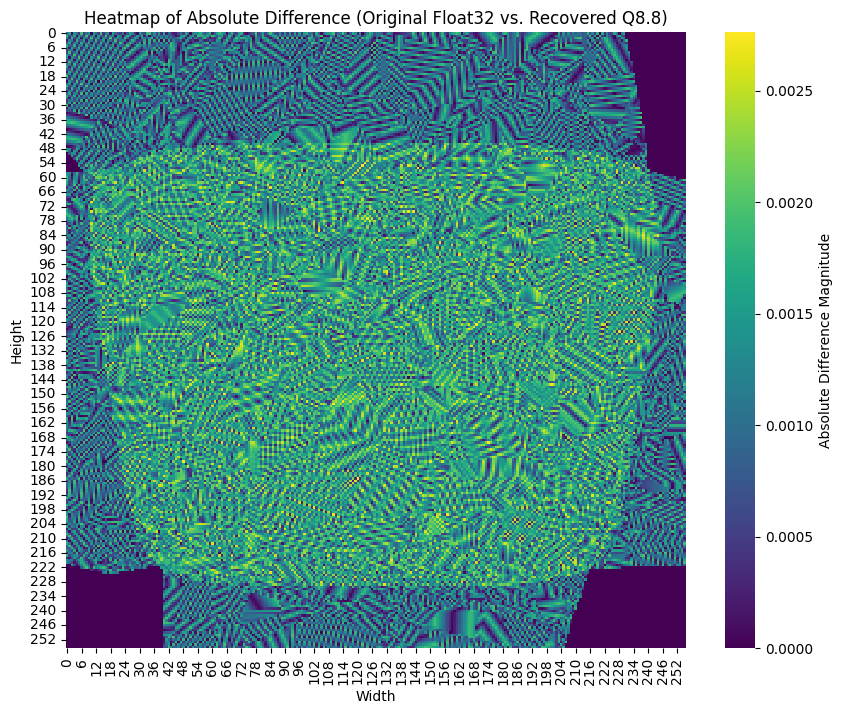

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Re-calculating 'grid' and 'diff_q88_original' to ensure they are defined
# (Assuming H, W, load_a1_weights, build_coord_grid, forward_a1_mlp are globally available from prior cells)
H, W = 256, 256
W1, b1, W2, b2, W3, b3 = load_a1_weights("#86-NN2_best.pth")
coords = build_coord_grid(H, W)
transformed = forward_a1_mlp(coords, W1, b1, W2, b2, W3, b3)
transformed = np.clip(transformed, 0.0, 1.0)
grid = (transformed * (W - 1)).astype(np.float32).reshape(H, W, 2)

# Re-calculate diff_q88_original (grid_q88_recovered is assumed to be globally available)
ys, xs = np.meshgrid(np.arange(H), np.arange(W), indexing='ij')
identity = np.stack([xs, ys], axis=-1).astype(np.float32)

disp_original = np.abs(grid - identity)
disp_q88_recovered = np.abs(grid_q88_recovered - identity)

diff_q88_original = np.abs(grid_q88_recovered - grid)

# Calculate the magnitude of the difference (e.g., L2 norm or sum of absolute differences)
diff_magnitude = np.linalg.norm(diff_q88_original, axis=2) # Euclidean distance

plt.figure(figsize=(10, 8))
sns.heatmap(diff_magnitude, cmap='viridis', cbar_kws={'label': 'Absolute Difference Magnitude'})
plt.title('Heatmap of Absolute Difference (Original Float32 vs. Recovered Q8.8)')
plt.xlabel('Width')
plt.ylabel('Height')
plt.show()

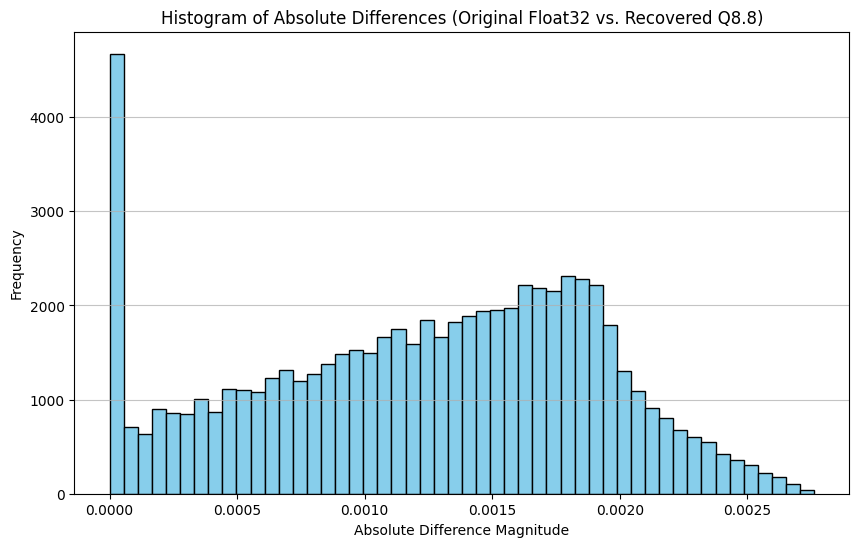

In [ ]:
plt.figure(figsize=(10, 6))
plt.hist(diff_magnitude.flatten(), bins=50, color='skyblue', edgecolor='black')
plt.title('Histogram of Absolute Differences (Original Float32 vs. Recovered Q8.8)')
plt.xlabel('Absolute Difference Magnitude')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.75)
plt.show()

In [ ]:
print(f"Maximum Absolute Difference Magnitude: {diff_magnitude.max():.9f}")
print(f"Minimum Absolute Difference Magnitude: {diff_magnitude.min():.9f}")
print(f"Average Absolute Difference Magnitude: {diff_magnitude.mean():.9f}")
print(f"Standard Deviation of Absolute Difference Magnitude: {diff_magnitude.std():.9f}")

Maximum Absolute Difference Magnitude: 0.002762136
Minimum Absolute Difference Magnitude: 0.000000000
Average Absolute Difference Magnitude: 0.001229724
Standard Deviation of Absolute Difference Magnitude: 0.000670411


In [ ]:
print("--- Original Float32 vs. Recovered Q8.8 for Spot Checks ---")
for (x, y) in [(0,0), (128,128), (255,255), (5,3), (200,100)]:
    gx_orig, gy_orig = grid[y, x]
    gx_q88, gy_q88 = grid_q88_recovered[y, x]
    print(f"(x={x}, y={y})\n  Original: x={gx_orig:.9f}  y={gy_orig:.9f}\n  Q8.8 Recov: x={gx_q88:.9f}  y={gy_q88:.9f}\n  Diff: x={(gx_orig-gx_q88):.9f}  y={(gy_orig-gy_q88):.9f}")

--- Original Float32 vs. Recovered Q8.8 for Spot Checks ---
(x=0, y=0)
  Original: x=18.582931519  y=0.000000000
  Q8.8 Recov: x=18.582031250  y=0.000000000
  Diff: x=0.000900269  y=0.000000000
(x=128, y=128)
  Original: x=128.681274414  y=96.407821655
  Q8.8 Recov: x=128.679687500  y=96.406250000
  Diff: x=0.001586914  y=0.001571655
(x=255, y=255)
  Original: x=255.000000000  y=255.000000000
  Q8.8 Recov: x=255.000000000  y=255.000000000
  Diff: x=0.000000000  y=0.000000000
(x=5, y=3)
  Original: x=20.378252029  y=0.000000000
  Q8.8 Recov: x=20.378906250  y=0.000000000
  Diff: x=-0.000654221  y=0.000000000
(x=200, y=100)
  Original: x=207.071166992  y=61.721946716
  Q8.8 Recov: x=207.070312500  y=61.722656250
  Diff: x=0.000854492  y=-0.000709534


In [ ]:
import torch, torch.nn as nn, numpy as np


In [ ]:

ckpt = torch.load("#86-NN2_best.pth", map_location="cpu")
sd = ckpt["model_state_dict"]

In [ ]:
# rebuild parametric_a1: 2->64->64->2, ReLU between, identity residual
class A1(nn.Module):
    def __init__(s):
        super().__init__()
        s.layer1 = nn.Linear(2, 64)
        s.layer2 = nn.Linear(64, 64)
        s.layer3 = nn.Linear(64, 2)
    def forward(s, x):
        h = torch.relu(s.layer1(x))
        h = torch.relu(s.layer2(h))
        return s.layer3(h) + x          # identity residual

In [ ]:
m = A1()
m.layer1.weight.data = sd["models.0.model.layer1.weight"]
m.layer1.bias.data   = sd["models.0.model.layer1.bias"]
m.layer2.weight.data = sd["models.0.model.layer2.weight"]
m.layer2.bias.data   = sd["models.0.model.layer2.bias"]
m.layer3.weight.data = sd["models.0.model.layer3.weight"]
m.layer3.bias.data   = sd["models.0.model.layer3.bias"]
m.eval()

A1(
  (layer1): Linear(in_features=2, out_features=64, bias=True)
  (layer2): Linear(in_features=64, out_features=64, bias=True)
  (layer3): Linear(in_features=64, out_features=2, bias=True)
)

In [ ]:
# same coords your script used, for the 5 spot-check pixels
W = 256
def coord(x, y):  # normalized [0,1], (x,y) order — matches build_coord_grid
    return torch.tensor([[x/(W-1), y/(W-1)]], dtype=torch.float32)

In [ ]:
for (x, y) in [(0,0),(128,128),(255,255),(5,3),(200,100)]:
    with torch.no_grad():
        out = m(coord(x, y))[0]
    out = torch.clamp(out, 0, 1) * (W-1)      # same clip+scale as your script
    print(f"(x={x},y={y}) -> PyTorch x={out[0]:.6f} y={out[1]:.6f}")

(x=0,y=0) -> PyTorch x=18.582928 y=0.000000
(x=128,y=128) -> PyTorch x=128.681274 y=96.407822
(x=255,y=255) -> PyTorch x=255.000000 y=255.000000
(x=5,y=3) -> PyTorch x=20.378248 y=0.000000
(x=200,y=100) -> PyTorch x=207.071167 y=61.721951


In [ ]:
# write Q8.8 LUT: 32-bit {y_q88[15:0], x_q88[15:0]} per line, row-major
def to_q88(v):
    # clamp to [0, 255.996], scale by 256, round, 16-bit unsigned
    q = int(round(float(v) * 256.0))
    return max(0, min(0xFFFF, q))

In [ ]:
import numpy as np
err = []
with open('lut.hex') as f:
    for y in range(H):
        for x in range(W):
            line = f.readline().strip()
            yq = int(line[0:4], 16); xq = int(line[4:8], 16)
            xv = xq / 256.0; yv = yq / 256.0
            err.append(abs(xv - grid[y,x,0]))
            err.append(abs(yv - grid[y,x,1]))
err = np.array(err)
print(f"Q8.8 quant error: max={err.max():.5f} mean={err.mean():.5f}  (expect < {1/256:.5f})")

Q8.8 quant error: max=0.00195 mean=0.00075  (expect < 0.00391)
